# Module C: frozen Dynaphos simulator, electrode layout, atlas
Builds the layout, runs the acceptance tests (plan section 5) and writes **`OUT/atlas_s{SEED}.npz`**, the parameter record and the Dynaphos params YAML. Modules B and E rebuild the identical layout from the same settings and check it against this atlas.

The layout is built once per kernel (kept in memory); the atlas is saved to disk. No training happens here.

In [1]:
import os, sys, json, math, time, subprocess, urllib.parse, urllib.request
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image, ImageDraw
import yaml, matplotlib.pyplot as plt
from scipy import ndimage
try: import dynaphos
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "dynaphos"]); import dynaphos
from dynaphos.simulator import GaussianSimulator
from dynaphos.utils import Map
from dynaphos.cortex_models import get_cortex_coordinates_grid, get_visual_field_coordinates_from_cortex_full

# ---- keep-in-memory helper: an object is built once per kernel; re-running a cell re-uses it ----
_mem = globals().setdefault("_mem", {})
def once(name, key, build, verbose=True):
    if name in globals() and _mem.get(name) == key:
        if verbose: print(f"[memory] {name}: already loaded, nothing recomputed")
        return globals()[name]
    globals()[name] = build(); _mem[name] = key; return globals()[name]


In [2]:
# ======== shared settings: keep IDENTICAL in the notebooks for modules B, C and E ========
# (they find each other's files through the OUT folder, whose name is built from these values)
QUICK   = True        # True: small end-to-end run (minutes). False: full run (use a GPU)
SOURCE  = "shapes"    # "shapes" = circle/square/triangle/line (plan step A1) | "quickdraw" = stroke drawings
CLASSES = ["circle", "square", "triangle", "line"]    # quickdraw example: ["apple", "bed", "cup", "house", "key", "scissors"]
SIZE, RES, FOV = 256, 256, 10.0     # image size, Dynaphos render size, field of view in degrees
N_ELEC  = 500         # electrodes used (subsampled from a cortical grid inside the field)
I_MAX   = 200.0       # uA. MY CHOICE: brightness ~0.95 here with Dynaphos defaults. Verify against the safety literature.
SEED    = 0           # one seed per run; set 1, 2 and re-run for the other seeds (each seed is cached separately)
N_IMG   = dict(train=60, val=20, test=30) if QUICK else dict(train=400, val=80, test=100)   # drawings per class
dev = "cuda" if torch.cuda.is_available() else "cpu"
NC  = len(CLASSES)
OUT = f"pipeline_out_{'quick' if QUICK else 'full'}_{SOURCE}_{NC}c_{N_ELEC}e_{RES}"; os.makedirs(OUT, exist_ok=True)
KEY = (SEED, N_ELEC, SOURCE, tuple(CLASSES), QUICK, RES, FOV, I_MAX)      # anything cached in memory is rebuilt only if this changes
QD_URL = "https://storage.googleapis.com/quickdraw_dataset/full/simplified/{}.ndjson"
print("device:", dev, "| outputs in", OUT)


device: cpu | outputs in pipeline_out_quick_shapes_4c_500e_256


In [3]:
# ---------------------------------------------------------------- Module C: frozen Dynaphos + electrode atlas
PARAMS_YAML = f"""
run: {{resolution: [{RES}, {RES}], view_angle: {FOV}, origin: [0, 0], min_angle: 0.001, fps: 35,
      gpu: {0 if torch.cuda.is_available() else 'null'}, print_stats: false, seed: 42, dtype: float32,
      use_gaussian_lut: false, batch_size: 0}}
display: {{screen_resolution: [1920, 1080], screen_diagonal: 13.3, dist_to_screen: 600}}
sampling: {{sampling_method: receptive_fields, RF_size: 0.5, stimulus_scale: 1.e-4}}
cortex_model: {{model: dipole, k: 17.3, a: 0.75, b: 120, alpha: 0.95, dropout_rate: 0.0, noise_scale: 0.4}}
temporal_dynamics: {{trace_increase_rate: 13.95528162, activation_decay_per_second: 0.00012340980408667956, trace_decay_per_second: 0.99949191}}
size: {{size_equation: sqrt, MD: 0.7, I_half: 40, slope_size: 0.08, current_spread: 675.e-6, radius_to_sigma: 0.5}}
brightness_saturation: {{cps_half: 1.057631326853325e-07, slope_brightness: 19152642.500946816}}
thresholding: {{use_threshold: true, rheobase: 23.9e-6, activation_threshold: 9.141886000943878e-08, activation_threshold_sd: 6.715877869833961e-08}}
default_stim: {{relative_stim_duration: 1, pw_default: 170.e-6, freq_default: 300}}
gabor: {{gabor_filtering: false, gamma: 1.5}}
"""   # = dynaphos config/params.yaml; changed: resolution, view_angle, dropout_rate 0 (dropout is applied at render time). Source: Dynaphos repo defaults.

class Phos:
    """Frozen Dynaphos + electrode atlas. render(I_uA) -> phosphene images; only active electrodes are summed (same maths as sim.__call__)."""
    def __init__(s, n_elec, seed):
        s.P = yaml.safe_load(PARAMS_YAML); rng = np.random.default_rng(seed)
        g = 32 if n_elec <= 1000 else 48
        cc = get_cortex_coordinates_grid(s.P["cortex_model"], g, g, x_max=40)       # g x g electrodes per hemisphere on the cortex
        x, y = get_visual_field_coordinates_from_cortex_full(s.P["cortex_model"], cc, rng).cartesian
        inb = (np.abs(x) < FOV / 2) & (np.abs(y) < FOV / 2)
        s.n_total, s.n_in_field = len(x), int(inb.sum())
        keep = rng.choice(np.flatnonzero(inb), min(n_elec, s.n_in_field), replace=False)
        s.sim = GaussianSimulator(s.P, Map(x=x[keep], y=y[keep]), rng)
        s.N, s.dev = s.sim.num_phosphenes, s.sim.data_kwargs["device"]
        co = s.sim.phosphene_maps.flatten(1).argmin(1).cpu().numpy()                 # pixel index of each phosphene centre
        s.xy = np.c_[x[keep], y[keep]]; s.px = np.c_[co % RES, co // RES]            # visual-field (deg) and pixel (col,row) centres
        p, dp, st = s.P["thresholding"], s.P["default_stim"], s.P["run"]["fps"]
        s.k_cur = st / (dp["pw_default"] * dp["freq_default"] * dp["relative_stim_duration"])   # activation -> current factor
        s.thr0 = s.sim.threshold.get().flatten()
        s.thr = ((p["rheobase"] + s.thr0.cpu().numpy() * s.k_cur) * 1e6 * 1.001 + 1e-3).astype(np.float32)   # uA, lowest current that shows a phosphene
        s.usable = s.thr <= I_MAX                                                    # electrodes that can ever be driven
        s.sim.reset(); s.sim.update(torch.full((s.N,), 128e-6, device=s.dev))        # size atlas at a reference current of 128 uA
        s.sigma_deg = s.sim.sigma.get().flatten().cpu().numpy(); s.sigma_px = s.sigma_deg / FOV * (RES - 1)
        s.ecc = np.linalg.norm(s.xy, axis=1)
        b = s.P["brightness_saturation"]; lvl = .7
        s.i70 = float((p["rheobase"] + (b["cps_half"] + math.log(lvl / (1 - lvl)) / b["slope_brightness"]) * s.k_cur) * 1e6)   # uA for 70 % brightness
        sg = torch.tensor(np.maximum(s.sigma_deg, 1.0 * FOV / (RES - 1)), device=s.dev)[:, None, None]
        W = torch.exp(-.5 * (s.sim.phosphene_maps / sg) ** 2).flatten(1); s.W = W / W.sum(1, keepdim=True)   # Gaussian sampling weights per electrode

    def render(s, I, p_drop=0., sigma_thr=0.):
        """I: (B,N) uA tensor (differentiable) -> (B,1,RES,RES). Optional electrode dropout and log-normal threshold jitter."""
        k = max(int((I > 0).sum(1).max()), 1); idx = I.topk(k, 1).indices; out = []
        for b in range(len(I)):
            if sigma_thr > 0: s.sim.threshold.state = (s.thr0 * torch.exp(sigma_thr * torch.randn_like(s.thr0))).view(-1, 1, 1)
            s.sim.reset(); s.sim.update(I[b].clamp_min(1e-3) * 1e-6)                 # clamp: sqrt(0) has an infinite gradient
            i = idx[b]; sg = s.sim.sigma.get().flatten()[i]; br = s.sim.brightness.get().flatten()[i]
            on = (s.sim.activation.get().flatten() > s.sim.threshold.get().flatten())[i].float() * (I[b][i] > 0).float()
            if p_drop > 0: on = on * (torch.rand(k, device=I.device) > p_drop).float()
            g = torch.exp(-.5 * (s.sim.phosphene_maps[i] / sg.clamp_min(1e-22)[:, None, None]) ** 2)
            out.append((on * br)[:, None, None].mul(g).sum(0))
        s.sim.threshold.state = s.thr0.view(-1, 1, 1)
        return torch.stack(out).clamp(0, 1)[:, None]

def save_atlas(C):
    np.savez(f"{OUT}/atlas_s{SEED}.npz", xy_deg=C.xy, px=C.px, sigma_deg=C.sigma_deg, thr_uA=C.thr, usable=C.usable, i70_uA=C.i70)

def check_atlas(C):
    f = f"{OUT}/atlas_s{SEED}.npz"
    if not os.path.exists(f): print("note: no atlas from the Module C notebook yet (run it once). The layout is rebuilt here from the same settings."); return
    a = np.load(f)
    assert a["xy_deg"].shape == C.xy.shape and np.allclose(a["xy_deg"], C.xy) and np.allclose(a["thr_uA"], C.thr, rtol=1e-3), \
        "this layout differs from the atlas written by the Module C notebook: settings or seed changed. Re-run Module C."
    print("layout matches the atlas written by the Module C notebook")


### C1/C3: build the layout (once) and save the atlas

In [4]:
C = once("C", KEY, lambda: Phos(N_ELEC, SEED))
save_atlas(C); print(f"Module C ready: {C.N} electrodes, {C.usable.sum()} usable; atlas saved to {OUT}/atlas_s{SEED}.npz")

Module C ready: 500 electrodes, 498 usable; atlas saved to pipeline_out_quick_shapes_4c_500e_256/atlas_s0.npz


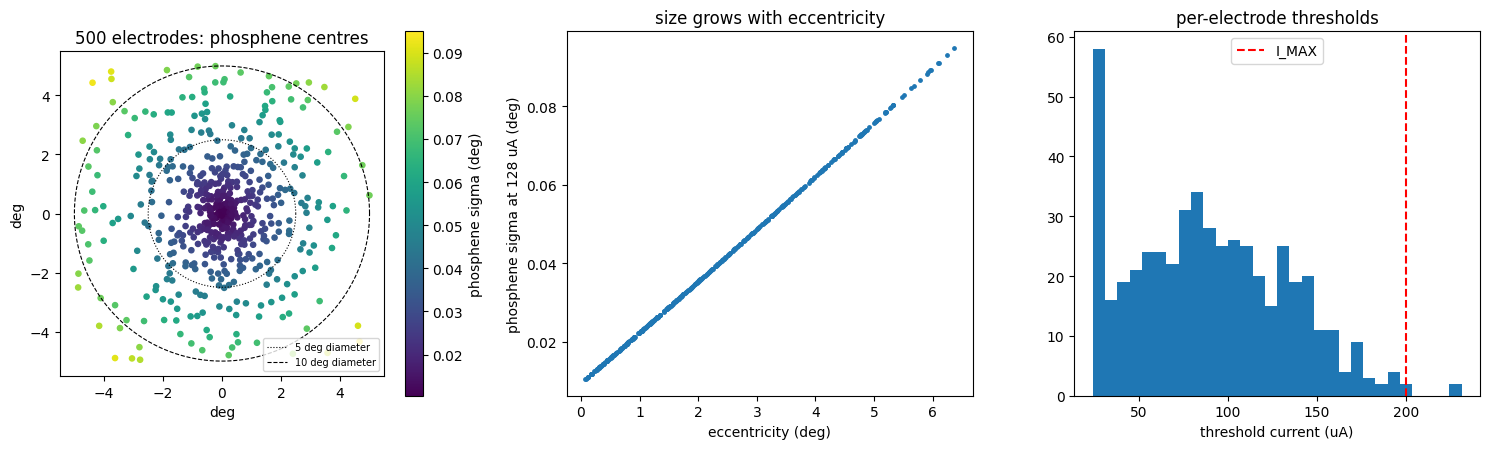

grid electrodes inside the central 10 deg field: 1315 of 1555 | in use: 500 | usable (threshold <= 200 uA): 498
in use: 300 within the central 5 deg (radius 2.5), 472 within the central 10 deg (radius 5)
=> maximum achievable K is about 498 for this layout; the K sweep must stay below it
nearest-neighbour spacing median 0.18 deg | phosphene sigma median 0.035 deg (0.90 px) | thresholds min/median/max 24/86/231 uA | I(70% brightness) 127 uA


In [5]:
# ---------- layout: phosphene centres against the 5 and 10 degree fields ----------
th = np.linspace(0, 2 * np.pi, 200); fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
sc = ax[0].scatter(C.xy[:, 0], C.xy[:, 1], c=C.sigma_deg, s=14, cmap="viridis"); plt.colorbar(sc, ax=ax[0], label="phosphene sigma (deg)")
for r, ls in ((2.5, ":"), (5, "--")): ax[0].plot(r * np.cos(th), r * np.sin(th), "k" + ls, lw=.8, label=f"{2 * r:.0f} deg diameter")
ax[0].set_aspect("equal"); ax[0].set_title(f"{C.N} electrodes: phosphene centres"); ax[0].legend(fontsize=7); ax[0].set_xlabel("deg"); ax[0].set_ylabel("deg")
ax[1].scatter(C.ecc, C.sigma_deg, s=6); ax[1].set_xlabel("eccentricity (deg)"); ax[1].set_ylabel("phosphene sigma at 128 uA (deg)"); ax[1].set_title("size grows with eccentricity")
ax[2].hist(C.thr, 30); ax[2].axvline(I_MAX, c="r", ls="--", label="I_MAX"); ax[2].set_xlabel("threshold current (uA)"); ax[2].set_title("per-electrode thresholds"); ax[2].legend()
plt.tight_layout(); plt.show()
n5 = int((C.ecc < 2.5).sum()); n10 = int((C.ecc < 5).sum())
print(f"grid electrodes inside the central {FOV:.0f} deg field: {C.n_in_field} of {C.n_total} | in use: {C.N} | usable (threshold <= {I_MAX:.0f} uA): {C.usable.sum()}")
print(f"in use: {n5} within the central 5 deg (radius 2.5), {n10} within the central 10 deg (radius 5)")
print(f"=> maximum achievable K is about {C.usable.sum()} for this layout; the K sweep must stay below it")
d = np.linalg.norm(C.xy[:, None] - C.xy[None], axis=-1) + np.eye(C.N) * 9
print(f"nearest-neighbour spacing median {np.median(d.min(1)):.2f} deg | phosphene sigma median {np.median(C.sigma_deg):.3f} deg ({np.median(C.sigma_px):.2f} px)"
      f" | thresholds min/median/max {C.thr.min():.0f}/{np.median(C.thr):.0f}/{C.thr.max():.0f} uA | I(70% brightness) {C.i70:.0f} uA")


### C4: random-current renders

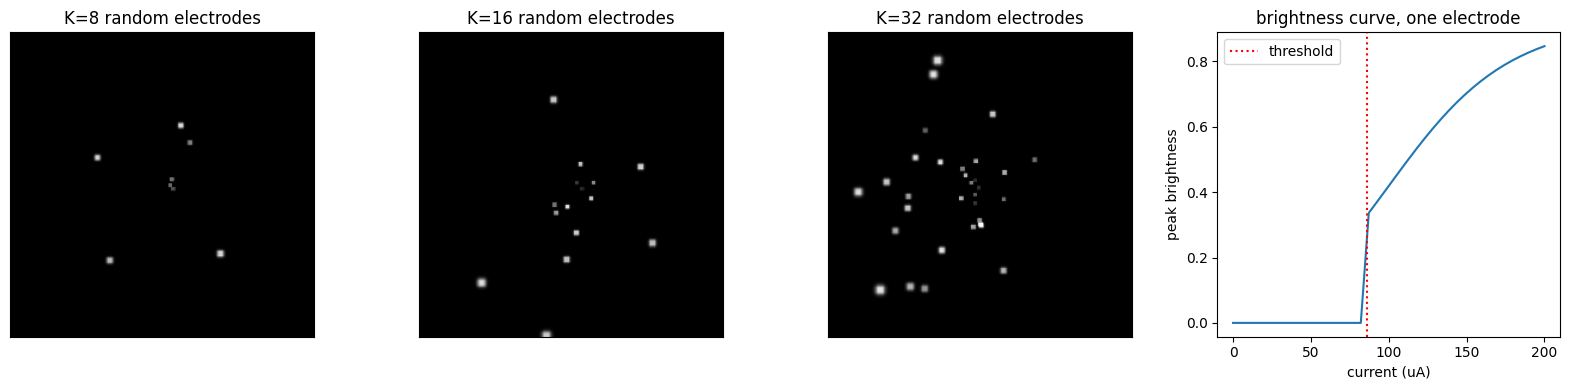

In [6]:
# ---------- C4: render test phosphenes from random currents (K random usable electrodes, amplitude uniform between threshold and I_MAX) ----------
rng = np.random.default_rng(1); us = np.flatnonzero(C.usable); fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, K in zip(ax[:3], (8, 16, 32)):
    sel = rng.choice(us, K, replace=False); I = np.zeros((1, C.N), np.float32); I[0, sel] = rng.uniform(C.thr[sel], I_MAX)
    P = C.render(torch.tensor(I, device=C.dev)); a.imshow(F.max_pool2d(P, 3, 1, 1)[0, 0].cpu(), cmap="gray", vmin=0, vmax=1)   # 3x3 dilation for display only
    a.set_title(f"K={K} random electrodes"); a.set_xticks([]); a.set_yticks([])
e = int(us[np.argsort(C.thr[us])[len(us) // 2]]); cur = np.linspace(0, I_MAX, 40).astype(np.float32); I = np.zeros((40, C.N), np.float32); I[:, e] = cur
with torch.no_grad(): peak = [C.render(torch.tensor(I[i:i + 1], device=C.dev)).max().item() for i in range(40)]
ax[3].plot(cur, peak); ax[3].axvline(C.thr[e], c="r", ls=":", label="threshold"); ax[3].set_xlabel("current (uA)"); ax[3].set_ylabel("peak brightness"); ax[3].set_title("brightness curve, one electrode"); ax[3].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/c4_random_renders_s{SEED}.png", dpi=110); plt.show()


### C5/C6: acceptance tests (smoke, threshold, monotonicity, gradients, determinism)

In [7]:
def c_tests(C):
    """Acceptance tests from plan section 5. Returns {test name: passed}."""
    res = {}; t = torch.zeros(1, C.N, device=C.dev)
    def ok(m, c): res[m] = bool(c); print(f"  [{'PASS' if c else 'FAIL'}] {m}")
    ok("zero current -> black image", C.render(t).max().item() == 0)
    e = int(np.flatnonzero(C.usable)[np.argsort(C.thr[C.usable])[C.usable.sum() // 2]])
    lo, hi = t.clone(), t.clone(); lo[0, e] = float(C.thr[e]) * .9; hi[0, e] = float(C.thr[e]) * 1.1
    ok("below threshold: nothing, above: phosphene", C.render(lo).max().item() == 0 and C.render(hi).max().item() > 0)
    tot = []
    for i in np.linspace(float(C.thr[e]), I_MAX, 8): a = t.clone(); a[0, e] = float(i); tot.append(C.render(a).sum().item())
    ok("brightness*size grows monotonically with current", all(np.diff(tot) >= -1e-6))
    inner, outer = C.sigma_px[C.ecc < 1.5], C.sigma_px[C.ecc > 3.5]
    ok(f"phosphenes grow with eccentricity ({inner.mean():.2f} px inner vs {outer.mean():.2f} px outer)", outer.mean() > inner.mean())
    rng = np.random.default_rng(0); us = np.flatnonzero(C.usable); sel = rng.choice(us, 20, replace=False)
    I = t.clone(); I[0, sel] = torch.tensor(np.minimum(C.thr[sel] * 1.5, I_MAX), device=C.dev)
    sub = rng.choice(np.setdiff1d(us, sel), 5, replace=False); I[0, sub] = torch.tensor(C.thr[sub] * .5, device=C.dev)   # sub-threshold but non-zero
    I.requires_grad_(True); C.render(I).sum().backward(); g = I.grad[0].cpu().numpy()
    ok("gradients finite", np.isfinite(g).all()); ok("gradient non-zero for active electrodes", (np.abs(g[sel]) > 0).mean() > .9)
    ok("gradient exactly zero for sub-threshold electrodes", (g[sub] == 0).all())
    with torch.no_grad():
        A, B = C.render(I.detach()), C.render(I.detach()); ok("rendering deterministic", torch.equal(A, B))
        C.sim.reset(); full = C.sim(I.detach()[0].clamp_min(1e-3) * 1e-6)
        d = (full - A[0, 0]).abs().max().item(); ok(f"sparse render equals Dynaphos' own dense render (max diff {d:.1e})", d < 1e-4)
    return res

test_results = once("test_results", KEY, lambda: c_tests(C))
print("ALL PASSED" if all(test_results.values()) else "SOME TESTS FAILED")

  [PASS] zero current -> black image
  [PASS] below threshold: nothing, above: phosphene
  [PASS] brightness*size grows monotonically with current
  [PASS] phosphenes grow with eccentricity (0.51 px inner vs 1.78 px outer)
  [PASS] gradients finite
  [PASS] gradient non-zero for active electrodes
  [PASS] gradient exactly zero for sub-threshold electrodes
  [PASS] rendering deterministic
  [PASS] sparse render equals Dynaphos' own dense render (max diff 0.0e+00)
ALL PASSED


In [8]:
# ---------- parameter record (Table 2) + config, written to OUT ----------
from importlib import metadata
try: ver = metadata.version("dynaphos")
except Exception: ver = getattr(dynaphos, "__version__", "unknown")
record = dict(dynaphos_version=ver, torch_version=torch.__version__, device=dev, resolution=RES, view_angle_deg=FOV, n_elec_requested=N_ELEC, n_elec_used=int(C.N), layout_seed=SEED,
              I_max_uA=I_MAX, I_max_source="own choice (verify against Dynaphos docs / stimulation-safety literature)", current_levels="continuous",
              threshold_uA=dict(min=float(C.thr.min()), median=float(np.median(C.thr)), max=float(C.thr.max())), i70_uA=C.i70,
              grid_electrodes_in_central_10deg=C.n_in_field, usable_electrodes=int(C.usable.sum()), frames=1, tests=test_results)
json.dump(record, open(f"{OUT}/c_record_s{SEED}.json", "w"), indent=1); open(f"{OUT}/dynaphos_params.yaml", "w").write(PARAMS_YAML)
print(json.dumps(record, indent=1)); print("\nsaved:", f"{OUT}/atlas_s{SEED}.npz", f"{OUT}/c_record_s{SEED}.json", f"{OUT}/dynaphos_params.yaml")


{
 "dynaphos_version": "0.1.3",
 "torch_version": "2.14.1+cpu",
 "device": "cpu",
 "resolution": 256,
 "view_angle_deg": 10.0,
 "n_elec_requested": 500,
 "n_elec_used": 500,
 "layout_seed": 0,
 "I_max_uA": 200.0,
 "I_max_source": "own choice (verify against Dynaphos docs / stimulation-safety literature)",
 "current_levels": "continuous",
 "threshold_uA": {
  "min": 23.92490005493164,
  "median": 86.18524932861328,
  "max": 231.2087860107422
 },
 "i70_uA": 126.84278730361594,
 "grid_electrodes_in_central_10deg": 1315,
 "usable_electrodes": 498,
 "frames": 1,
 "tests": {
  "zero current -> black image": true,
  "below threshold: nothing, above: phosphene": true,
  "brightness*size grows monotonically with current": true,
  "phosphenes grow with eccentricity (0.51 px inner vs 1.78 px outer)": true,
  "gradients finite": true,
  "gradient non-zero for active electrodes": true,
  "gradient exactly zero for sub-threshold electrodes": true,
  "rendering deterministic": true,
  "sparse render 